<a href="https://colab.research.google.com/github/eduzegarra/grade_01/blob/main/example_VMT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Example: Processing and analyzing data for district of Villa Maria del Triunfo

##1. Setup & Environment

In [ ]:
# Clear all variables in the namespace to start fresh
%reset -f

In [ ]:
# Execute this empty cell to force the Colab variable panel to refresh and update
pass

In [ ]:
# Imports critical Python libraries: pandas for tabular data,
#  geopandas for geospatial vector data and matplotlib for generating plots.

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [ ]:
# Create a working directory
import os
os.mkdir('/content/sample_data/short_course')

In [ ]:
# Changes the working directory to the target path containing the study files (/content/sample_data/short_course) and lists them.
# Identifies 8 files, including GPKGs (geopackages containing shape polygons/points) and GeoTIFFs (raster grids for elevations and slopes).

os.chdir('/content/sample_data/short_course')
!ls

## 2. Loading Spatial & Tabular Datasets: initial exploration

In [ ]:
# upolading 6 files from wrking directory and assign to python variables
censo_sel = pd.read_csv("censo_sel.csv")
comedores_clip = gpd.read_file("comedores_clip.gpkg")
ollas_clip = gpd.read_file("ollas_clip.gpkg")
manzanas_clip = gpd.read_file("manzanas_clip.gpkg")
grid_clip=gpd.read_file('grid_clip.gpkg')
distritos_LIMA = gpd.read_file('distritos_LIMA.gpkg')

In [42]:
# Prints the number of observations (rows) in each loaded layer,
# revealing that we have 8,123 blocks (manzanas), 290 Ollas, 198 Comedores, and 327 grid units.

print("Nomber of observations")
print("-"*110)
print('Manzanas (blocks):',len(manzanas_clip),'| Ollas:', len(ollas_clip),'| Comedores:', len(comedores_clip),
      '| Grid:', len(grid_clip) , '| Census:', len(censo_sel), '| Districts:', len(distritos_LIMA))
print("-"*110)

Nomber of observations
--------------------------------------------------------------------------------------------------------------
Manzanas (blocks): 8123 | Ollas: 290 | Comedores: 198 | Grid: 327 | Census: 3832 | Districts: 43
--------------------------------------------------------------------------------------------------------------


In [37]:
# Audits and outputs the columns (features) of every dataset to verify attributes such as geographic identifiers (idmanzana, id_grid),
# geographic shapes (geometry), and census variables (population, roof types, electricity access, etc.).

print('VARIABLES EN EACH FILE')
print("-"*100)
print('manzanas_clip:', manzanas_clip.columns)
print("-"*100)
print('ollas_clip:', ollas_clip.columns)
print("-"*100)
print('comedores_clip:',comedores_clip.columns),
print("-"*100)
print('grid_clip:',grid_clip.columns)
print("-"*100)
print('censo_sel:', censo_sel.columns)
print("-"*100)
print('districts:', distritos_LIMA.columns)

VARIABLES EN EACH FILE
----------------------------------------------------------------------------------------------------
manzanas_clip: Index(['idmanzana', 'ubigeo', 'nombdist', 'nombcccpp', 'tipo', 'geometry'], dtype='object')
----------------------------------------------------------------------------------------------------
ollas_clip: Index(['fid_olla', 'o_distrito', 'o_nombre', 'o_direccion', 'o_codigo',
       'o_estado', 'o_benef', 'o_dist_near_comedor', 'o_manual', 'geometry'],
      dtype='object')
----------------------------------------------------------------------------------------------------
comedores_clip: Index(['fid_comedor', 'co_distrito', 'co_nombre', 'co_direccion', 'co_codigo',
       'co_estado', 'co_benef', 'geometry'],
      dtype='object')
----------------------------------------------------------------------------------------------------
grid_clip: Index(['fid_grid', 'id_grid', 'geometry'], dtype='object')
--------------------------------------------------

###General strategy:
1. Relate Ollas to Blocks (using spatial join)
2. Generate number of ollas and mean values of distance to nearest comedor and socio-economic variables for each block
3. Use grid to aggregate values for final database

## 3. Spatial Visualization of Layers

In [ ]:
### Location of VMT in Lima Metropolitana
axis=distritos_LIMA.boundary.plot(figsize=(16,10), linewidth=0.5)
manzanas_clip.plot(ax=axis)
axis.set_title("Lima Metropolitana districts")
plt.show()


In [ ]:
## Location of Comedores and Ollas in VMT
vmt_district = distritos_LIMA[distritos_LIMA['NOMBDIST'] == 'VILLA MARIA DEL TRIUNFO']
axis=vmt_district.boundary.plot(figsize=(14,8), linewidth=0.5)
manzanas_clip.boundary.plot(ax=axis, label='Blocks', color='green', linewidth=0.3, alpha=0.5)
grid_clip.boundary.plot(ax=axis, label='Grid', color='black', linewidth=0.5)
ollas_clip.plot(ax=axis, color='red', markersize=3, label='Ollas')
comedores_clip.plot(ax=axis, color='blue', markersize=3, label='Comedores')
axis.set_title("Comedores and Ollas in VMT")
plt.legend()
plt.show()

## 4. Relating Ollas to Blocks

In [43]:
# Performs a nearest-neighbor spatial join (gpd.sjoin_nearest)
# to link each Olla point to its closest census block. It records this distance as dist_01.
# (dist_01==0 implies Olla is inside the nearest block)
join_01=gpd.sjoin_nearest(ollas_clip,manzanas_clip, how='left', distance_col='dist_01')[['idmanzana','fid_olla', 'o_distrito', 'o_nombre', 'o_direccion', 'o_codigo',
       'o_estado', 'o_benef', 'o_dist_near_comedor', 'o_manual','dist_01']]

In [44]:
join_01.describe()

,fid_olla,o_benef,o_dist_near_comedor,dist_01
count,290.000000,290.000000,290.000000,290.000000
mean,2991.044828,68.517241,488.169867,3.944072
std,200.368574,28.144733,486.089075,10.371150
min,1951.000000,16.000000,5.828028,0.000000
25%,2946.250000,50.000000,249.442723,0.000000
50%,3019.500000,64.500000,368.233483,0.000000
75%,3091.750000,85.000000,560.478096,2.952202
max,3166.000000,196.000000,3904.510950,72.154261


In [45]:
## There are Ollas that do not overlap with blocks (47.2%), so will not have Census data. We need to solve this problem later on.
(join_01.dist_01>0).sum()/len(join_01)

np.float64(0.4724137931034483)

In [47]:
# Performs a standard tabular merge to bring the joined
# block-to-Olla details back into the master block dataset.

merge_01=manzanas_clip.merge(join_01,on='idmanzana', how='left')

In [48]:
merge_01.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 8138 entries, 0 to 8137
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   idmanzana            8138 non-null   object  
 1   ubigeo               8138 non-null   object  
 2   nombdist             8138 non-null   object  
 3   nombcccpp            8138 non-null   object  
 4   tipo                 8138 non-null   object  
 5   geometry             8138 non-null   geometry
 6   fid_olla             290 non-null    float64 
 7   o_distrito           290 non-null    object  
 8   o_nombre             290 non-null    object  
 9   o_direccion          290 non-null    object  
 10  o_codigo             290 non-null    object  
 11  o_estado             290 non-null    object  
 12  o_benef              290 non-null    float64 
 13  o_dist_near_comedor  290 non-null    float64 
 14  o_manual             290 non-null    object  
 15  dist_01      

In [49]:
# Groups the block dataset by idmanzana to calculate:
# 1.	The total number of Ollas in that block (num_ollas).
# 2.	The average walking distance from those Ollas to the nearest comedor (mean_dist_walk).

group_01=merge_01.rename(columns={'o_codigo':'num_ollas',
    'o_dist_near_comedor':'mean_dist_walk'}).groupby('idmanzana').agg({'num_ollas':'count'
    ,'mean_dist_walk':'mean'})

In [50]:
### There are Ollas in 275 blocks (maximum=4 Ollas in 1 block)
group_01.describe()

,num_ollas,mean_dist_walk
count,8123.000000,275.000000
mean,0.035701,485.825787
std,0.197137,471.365920
min,0.000000,45.265922
25%,0.000000,249.567383
50%,0.000000,368.287449
75%,0.000000,557.284057
max,4.000000,3904.510950


In [53]:
# Integrates these block-level aggregated variables back into manzanas_clip and
manz_olla=manzanas_clip.merge(group_01,on='idmanzana',how='left')

# then calculates the straight-line (linear) distance from every block centroid
# to the nearest Comedor Populares (d_comedor).
join_02=gpd.sjoin_nearest(manz_olla,comedores_clip,how="left", distance_col="d_comedor")[['idmanzana','d_comedor']]

# Cleans and integrates that linear comedor distance variable into the master block framework.
join_02=join_02.groupby('idmanzana').agg({'d_comedor':'mean'})
manz_olla=manz_olla.merge(join_02,on='idmanzana', how='left')

In [54]:
manz_olla.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 8123 entries, 0 to 8122
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   idmanzana       8123 non-null   object  
 1   ubigeo          8123 non-null   object  
 2   nombdist        8123 non-null   object  
 3   nombcccpp       8123 non-null   object  
 4   tipo            8123 non-null   object  
 5   geometry        8123 non-null   geometry
 6   num_ollas       8123 non-null   int64   
 7   mean_dist_walk  275 non-null    float64 
 8   d_comedor       8123 non-null   float64 
dtypes: float64(2), geometry(1), int64(1), object(5)
memory usage: 571.3+ KB


In [55]:
# Addresses the missing distance data by filling the NaN values of mean_dist_walk
#  with the computed straight-line linear distance to the nearest Comedor for blocks without Ollas.

manz_olla.loc[manz_olla.mean_dist_walk.isna(),'mean_dist_walk']=0
manz_olla.loc[manz_olla.mean_dist_walk==0,'mean_dist_walk']=manz_olla.d_comedor

In [56]:
manz_olla.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 8123 entries, 0 to 8122
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   idmanzana       8123 non-null   object  
 1   ubigeo          8123 non-null   object  
 2   nombdist        8123 non-null   object  
 3   nombcccpp       8123 non-null   object  
 4   tipo            8123 non-null   object  
 5   geometry        8123 non-null   geometry
 6   num_ollas       8123 non-null   int64   
 7   mean_dist_walk  8123 non-null   float64 
 8   d_comedor       8123 non-null   float64 
dtypes: float64(2), geometry(1), int64(1), object(5)
memory usage: 571.3+ KB


In [57]:
# Checks how many blocks have custom walking distances instead of pure linear calculations (275 blocks)
(~(manz_olla.mean_dist_walk==manz_olla.d_comedor)).sum()

np.int64(275)

##5. Integrating raw census data with spatial units (blocks)

In [58]:
# Merges the spatial blocks data with the tabular census attributes (censo_sel)
# on idmanzana
merge_02=manz_olla.merge(censo_sel, on='idmanzana', how='left')

In [60]:
# There are 3832 blocks with census data out of 8123 blocks
merge_02.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 8123 entries, 0 to 8122
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   idmanzana       8123 non-null   object  
 1   ubigeo          8123 non-null   object  
 2   nombdist        8123 non-null   object  
 3   nombcccpp       8123 non-null   object  
 4   tipo            8123 non-null   object  
 5   geometry        8123 non-null   geometry
 6   num_ollas       8123 non-null   int64   
 7   mean_dist_walk  8123 non-null   float64 
 8   d_comedor       8123 non-null   float64 
 9   Unnamed: 0      3832 non-null   float64 
 10  distrito        3832 non-null   object  
 11  viviendas       3832 non-null   float64 
 12  poblacion       3832 non-null   float64 
 13  t_agua          3832 non-null   float64 
 14  t_luz           3832 non-null   float64 
 15  t_pared         3832 non-null   float64 
 16  t_techo         3832 non-null   float64 
 17  t_piso

In [61]:
## Creates a binary flag con_censo indicating whether a block has valid census records.
#  It shows that 3,832 blocks have census data, while 4,291 do not (when t_agua is NaN).
merge_02['con_censo']=1
merge_02.loc[merge_02.t_agua.isna(),'con_censo']=0
merge_02.con_censo.value_counts()

,count
con_censo,
0,4291
1,3832


In [62]:
#  Subsets blocks that contain an Olla but lack census info into a dataframe named ollas_sin_censo.
ollas_sin_censo=merge_02[(merge_02.con_censo==0) & (merge_02.num_ollas>0)]
ollas_sin_censo=ollas_sin_censo[['nombdist','geometry','num_ollas', 'mean_dist_walk', 'd_comedor']]

In [64]:
## There are 155 Ollas that are not associated to a block with census data
len(ollas_sin_censo)

155

In [68]:
## Filters out a clean subset containing only blocks with complete census data (merge_03) with 3832 blocks
merge_03=merge_02[merge_02.con_censo==1]
len(merge_03)

3832

In [73]:
# Employs gpd.sjoin_nearest to impute missing census data for the 'non-census' Olla blocks
# by matching them to the nearest block that do have census information.

manz_append=gpd.sjoin_nearest(ollas_sin_censo,merge_03,how="left")

In [74]:
## Cleans the dataframe 'manz_append' with 155 blocks
manz_append=manz_append[['nombdist_left', 'geometry', 'num_ollas_left', 'mean_dist_walk_left',
       'd_comedor_left', 'idmanzana', 'ubigeo',
       'nombcccpp', 'tipo', 'viviendas', 'poblacion', 't_agua', 't_luz', 't_pared', 't_techo',
       't_piso', 't_carbon', 't_lena', 't_nococin', 't_jhsolte', 't_jhmigra',
       't_jhnoesp', 't_jhnotrab', 't_child5', 't_adulmay', 't_jh30', 't_jh70',
       'con_censo']].rename(columns={'nombdist_left':'nombdist','num_ollas_left':'num_ollas',
        'mean_dist_walk_left':'mean_dist_walk','d_comedor_left':'d_comedor' })
len(manz_append)

155

In [77]:
# Recover the 155 matched imputed records back to the master set (merge_03),
# creating a final unified dataframe of 3,987 blocks (merge_04).
merge_04=pd.concat([merge_03, manz_append])
len(merge_04)

3987

In [79]:
### Keep useful columns
merge_04=merge_04[['idmanzana', 'geometry',
       'num_ollas', 'mean_dist_walk', 'd_comedor', 'distrito', 'viviendas',
       'poblacion', 't_agua', 't_luz', 't_pared', 't_techo', 't_piso',
       't_carbon', 't_lena', 't_nococin', 't_jhsolte', 't_jhmigra',
       't_jhnoesp', 't_jhnotrab', 't_child5', 't_adulmay', 't_jh30', 't_jh70']]

In [80]:
merge_04.shape

(3987, 24)

### Generating additional spatial data like altitude and slope values per block

In [81]:
#  Generate variable for block area in square kilometers.
merge_04['area_km2']=merge_04.geometry.area/1000000

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


In [82]:
# Imports raster tools (rasterio) for reading raster files (tiff)

import rasterio
from rasterio.plot import show
import numpy as np

In [83]:
# Opens the Digital Elevation Model (DEM) and slope rasters.
altitude = rasterio.open("dem_LIMA.tif")
slopes = rasterio.open('slopes_LIMA.tif')

In [84]:
# Extracts the exact elevation (altitude) and inclination (slope) from the raster
# maps at the centroid coordinates of each block and appends them to merge_04.

manz_centroides=merge_04.geometry.centroid
lista_coord=[(x,y) for x,y in zip(manz_centroides.geometry.x, manz_centroides.geometry.y)]

merge_04['slope'] = [cc[0] for cc in slopes.sample(lista_coord)]
merge_04['altitude']=[cc[0] for cc in altitude.sample(lista_coord)]
merge_04.loc[merge_04.slope<=0,'slope']=0

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


## 6. Aggregating to a grid for final analysis

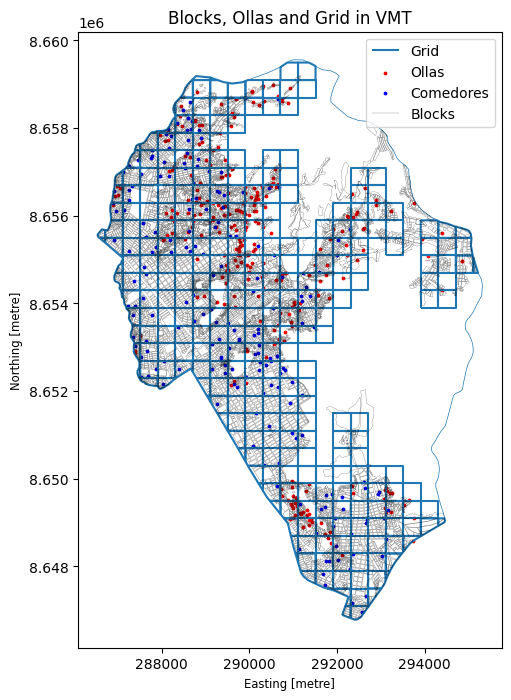

In [87]:
## Remember the grid to aggregate data with homogeneous spatial units
axis=vmt_district.boundary.plot(figsize=(14,8), linewidth=0.5)
axis.set_title("Blocks, Ollas and Grid in VMT")
grid_clip.boundary.plot(ax=axis, label='Grid')
ollas_clip.plot(ax=axis, color='red', markersize=3, label='Ollas')
comedores_clip.plot(ax=axis, color='blue', markersize=3, label='Comedores')
manzanas_clip.boundary.plot(ax=axis, linewidth=0.2, color='black', alpha=0.65, label='Blocks')
plt.legend()
plt.show()

In [88]:
len(grid_clip)

327

In [89]:
#  Transforms block polygons into points (centroids) so they can be matched inside the analytical grid units.
merge_04['geometry'] = merge_04.geometry.centroid

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


In [90]:
len(merge_04)

3987

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

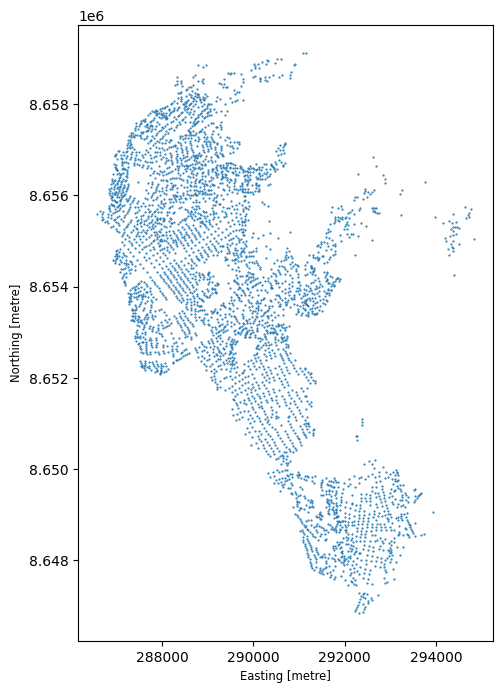

In [91]:
# Looking at blocks converted to points
merge_04.plot(markersize=0.3, figsize=(12,8))

In [92]:
#  Executes a spatial intersection join to link each centroid to its corresponding grid cell in grid_clip.
join_04=gpd.sjoin(grid_clip,merge_04, how='left', predicate='intersects')

In [93]:
# Groups the data by grid ID (id_grid) and aggregates features.
# For example, sum of Ollas, sum of population, average slope,
# and average rate of households with running water (t_agua).

group_04=join_04.groupby('id_grid', as_index=False).agg({'num_ollas':'sum', 'mean_dist_walk':'mean', 'd_comedor':'mean',
       'viviendas':'sum', 'poblacion':'sum', 't_agua':'mean', 't_luz':'mean', 't_pared':'mean',
       't_techo':'mean', 't_piso':'mean', 't_carbon':'mean', 't_lena':'mean', 't_nococin':'mean', 't_jhsolte':'mean',
       't_jhmigra':'mean', 't_jhnoesp':'mean', 't_jhnotrab':'mean', 't_child5':'mean', 't_adulmay':'mean',
       't_jh30':'mean', 't_jh70':'mean', 'slope':'mean', 'altitude':'mean', 'area_km2':'sum'})

In [95]:
group_04.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
id_grid,327.0,14690.354740,1069.977204,12626.000000,13893.500000,14742.000000,15498.000000,17292.000000
num_ollas,327.0,0.880734,1.580507,0.000000,0.000000,0.000000,1.000000,10.000000
mean_dist_walk,280.0,323.638803,467.497839,13.549433,114.194383,183.499278,292.827606,3633.704915
d_comedor,280.0,281.448096,404.023987,13.549433,105.727529,163.984715,254.812927,2557.380256
viviendas,327.0,270.892966,233.708455,0.000000,42.500000,230.000000,443.000000,924.000000
poblacion,327.0,1082.360856,1030.598756,0.000000,116.000000,835.000000,1748.500000,4784.000000
t_agua,280.0,0.322405,0.312820,0.000000,0.064860,0.163167,0.551782,1.000000
t_luz,280.0,0.136616,0.221900,0.000000,0.002525,0.023544,0.162519,0.945946
t_pared,280.0,0.300840,0.268320,0.000000,0.060854,0.236062,0.471590,1.000000
t_techo,280.0,0.468073,0.234733,0.000000,0.266066,0.441095,0.649060,1.000000


In [96]:
join_04.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
fid_grid,4032.0,14320.588790,925.217526,1.262600e+04,13679.000000,14120.000000,14970.250000,17292.000000
id_grid,4032.0,14320.588790,925.217526,1.262600e+04,13679.000000,14120.000000,14970.250000,17292.000000
index_right,3985.0,4357.888833,2273.034354,5.000000e+00,2684.000000,4551.000000,6206.000000,8118.000000
num_ollas,3985.0,0.072271,0.275864,0.000000e+00,0.000000,0.000000,0.000000,4.000000
mean_dist_walk,3985.0,195.051520,242.660050,0.000000e+00,76.128924,145.736168,245.063400,3633.704915
d_comedor,3985.0,179.742695,218.335273,0.000000e+00,73.346995,141.424226,230.702050,2557.380256
viviendas,3985.0,22.228858,14.173917,3.000000e+00,12.000000,18.000000,28.000000,165.000000
poblacion,3985.0,88.816060,65.524609,3.000000e+01,42.000000,68.000000,117.000000,1658.000000
t_agua,3985.0,0.233729,0.331848,0.000000e+00,0.000000,0.064516,0.310345,1.000000
t_luz,3985.0,0.075306,0.193364,0.000000e+00,0.000000,0.000000,0.000000,1.000000


In [97]:
# Merges aggregated metrics back into the master grid geometry to produce grid_merge.

grid_merge=grid_clip.merge(group_04, on='id_grid', how='left')

In [98]:
grid_merge.columns

Index(['fid_grid', 'id_grid', 'geometry', 'num_ollas', 'mean_dist_walk',
       'd_comedor', 'viviendas', 'poblacion', 't_agua', 't_luz', 't_pared',
       't_techo', 't_piso', 't_carbon', 't_lena', 't_nococin', 't_jhsolte',
       't_jhmigra', 't_jhnoesp', 't_jhnotrab', 't_child5', 't_adulmay',
       't_jh30', 't_jh70', 'slope', 'altitude', 'area_km2'],
      dtype='object')

In [99]:
grid_merge.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 327 entries, 0 to 326
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   fid_grid        327 non-null    int64   
 1   id_grid         327 non-null    int64   
 2   geometry        327 non-null    geometry
 3   num_ollas       327 non-null    float64 
 4   mean_dist_walk  280 non-null    float64 
 5   d_comedor       280 non-null    float64 
 6   viviendas       327 non-null    float64 
 7   poblacion       327 non-null    float64 
 8   t_agua          280 non-null    float64 
 9   t_luz           280 non-null    float64 
 10  t_pared         280 non-null    float64 
 11  t_techo         280 non-null    float64 
 12  t_piso          280 non-null    float64 
 13  t_carbon        280 non-null    float64 
 14  t_lena          280 non-null    float64 
 15  t_nococin       280 non-null    float64 
 16  t_jhsolte       280 non-null    float64 
 17  t_jhmigr

In [100]:
# Drops empty zones to create base_clean and computes the area of each individual grid cell.
base_clean=grid_merge.dropna(subset=['mean_dist_walk'])

In [101]:
len(base_clean)

280

In [102]:
# Computes population densities using both local block-level areas (pop_dens_01)
# and the overall grid square areas (pop_dens_02).
base_clean['area_cell_km2']=base_clean.geometry.area/1000000
base_clean['pop_dens_01']=base_clean.poblacion/base_clean.area_km2
base_clean['pop_dens_02']=base_clean.poblacion/base_clean.area_cell_km2

/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/usr/local/lib/python3.13/dist-packages/geopandas/geodataframe.py:2011: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value 

In [103]:
## This is the final database for analysis
base_clean.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
fid_grid,280.0,14629.264286,1046.041153,12626.000000,13841.000000,14544.500000,15398.250000,17080.000000
id_grid,280.0,14629.264286,1046.041153,12626.000000,13841.000000,14544.500000,15398.250000,17080.000000
num_ollas,280.0,1.028571,1.663191,0.000000,0.000000,0.000000,2.000000,10.000000
mean_dist_walk,280.0,323.638803,467.497839,13.549433,114.194383,183.499278,292.827606,3633.704915
d_comedor,280.0,281.448096,404.023987,13.549433,105.727529,163.984715,254.812927,2557.380256
viviendas,280.0,316.364286,222.224521,8.000000,129.750000,298.500000,477.750000,924.000000
poblacion,280.0,1264.042857,1005.277371,31.000000,386.250000,1117.500000,1963.750000,4784.000000
t_agua,280.0,0.322405,0.312820,0.000000,0.064860,0.163167,0.551782,1.000000
t_luz,280.0,0.136616,0.221900,0.000000,0.002525,0.023544,0.162519,0.945946
t_pared,280.0,0.300840,0.268320,0.000000,0.060854,0.236062,0.471590,1.000000


In [104]:
#  Filters out the top 1% density outliers from base_clean to prevent statistical leverage issues.
top_1_percentile_01 = base_clean['pop_dens_01'].quantile(0.99)
top_1_percentile_02 = base_clean['pop_dens_02'].quantile(0.99)

In [105]:
base_clean=base_clean[(base_clean['pop_dens_01'] < top_1_percentile_01) & (base_clean['pop_dens_02'] < top_1_percentile_02)]
print(f"New shape of base_clean after dropping top 1%: {base_clean.shape}")
display(base_clean.head())

New shape of base_clean after dropping top 1%: (275, 30)


,fid_grid,id_grid,geometry,num_ollas,mean_dist_walk,d_comedor,viviendas,poblacion,t_agua,t_luz,...,t_child5,t_adulmay,t_jh30,t_jh70,slope,altitude,area_km2,area_cell_km2,pop_dens_01,pop_dens_02
0,15616,15616,"MULTIPOLYGON (((292312.698 8647095.309, 292312...",0.0,172.088204,172.088204,180.0,639.0,0.005405,0.010811,...,0.107513,0.035994,0.097487,0.038599,0.759680,106.200000,0.024114,0.038735,26499.136983,16496.716745
1,15828,15828,"MULTIPOLYGON (((292712.698 8647095.309, 292712...",0.0,132.393361,132.393361,113.0,452.0,0.000000,0.000000,...,0.079713,0.065639,0.086789,0.107611,1.588636,106.166667,0.017582,0.091035,25708.354412,4965.109095
5,15615,15615,"MULTIPOLYGON (((292312.698 8647495.309, 292312...",0.0,284.493992,284.493992,33.0,131.0,0.037037,0.000000,...,0.153128,0.034685,0.121693,0.000000,1.714091,112.000000,0.026805,0.066421,4887.092114,1972.259387
6,15827,15827,"MULTIPOLYGON (((292712.698 8647495.309, 292712...",0.0,85.097180,85.097180,230.0,821.0,0.032015,0.000000,...,0.078533,0.068916,0.071444,0.083551,1.281452,95.916667,0.045277,0.160000,18132.942214,5131.250000
7,16039,16039,"MULTIPOLYGON (((293013.065 8647495.309, 292747...",0.0,13.549433,13.549433,47.0,211.0,0.914894,0.255319,...,0.113744,0.018957,0.075472,0.018868,0.387105,77.000000,0.011103,0.063364,19003.177099,3329.979961


In [ ]:
base_clean.columns

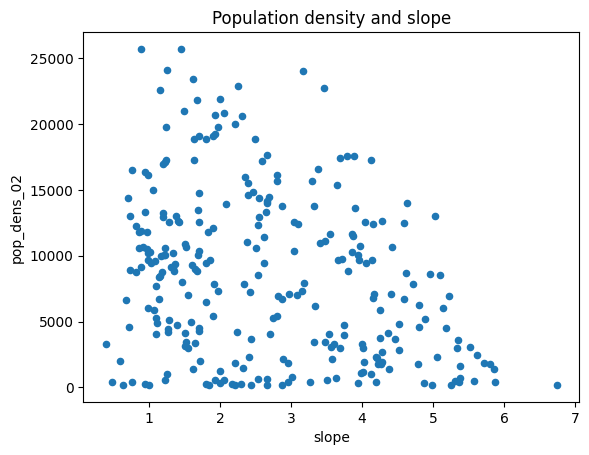

In [106]:
## Plots a scatter visualization showing the relationship between slope (terrain) and population density.
base_clean.plot.scatter(x='slope',y='pop_dens_02')
plt.title("Population density and slope")
plt.show()

In [ ]:
base_clean.describe().transpose()

##7. Econometric & Spatial Regression Modeling

In [107]:
# Imports statistical packages and applies a log-transformation
# to heavily skewed variables (population, distance, elevation)
# to normalize distributions for regression models.

import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
import numpy as np

In [108]:
# Creates a binary indicator column has_ollas
base_clean['has_ollas']=0
base_clean.loc[base_clean.num_ollas>0,'has_ollas']=1

In [109]:
base_clean['log_pob']=np.log(np.maximum(base_clean["pop_dens_02"], 1))
base_clean['log_altitude']=np.log(np.maximum(base_clean["altitude"], 1))
base_clean['log_distance']=np.log(np.maximum(base_clean["mean_dist_walk"], 1))
base_clean['log_dist_linear']=np.log(np.maximum(base_clean["d_comedor"], 1))


In [110]:
base_exclude=base_clean.copy()

In [111]:
base_exclude.shape

(275, 35)

In [112]:
formula = ("has_ollas ~ log_distance + "
    "t_agua + "
    "t_piso + "
    "slope + "
    "log_altitude + "
    "log_pob")
formula1 = ("has_ollas ~ log_dist_linear + "
    "t_agua + "
    "t_piso + "
    "slope + "
    "log_altitude")

In [113]:
probit_model = smf.probit(formula=formula, data=base_exclude).fit(cov_type="HC1")
print(probit_model.summary())

Optimization terminated successfully.
         Current function value: 0.442622
         Iterations 6
                          Probit Regression Results                           
Dep. Variable:              has_ollas   No. Observations:                  275
Model:                         Probit   Df Residuals:                      268
Method:                           MLE   Df Model:                            6
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.3520
Time:                        11:40:12   Log-Likelihood:                -121.72
converged:                       True   LL-Null:                       -187.84
Covariance Type:                  HC1   LLR p-value:                 4.339e-26
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      -12.2537      2.931     -4.180      0.000     -17.999      -6.508
log_distance     0.4114

In [114]:
poisson_model = smf.poisson(formula=formula,
                            data=base_exclude).fit(cov_type="HC1")
print(poisson_model.summary())

Optimization terminated successfully.
         Current function value: 0.676056
         Iterations 6
                          Poisson Regression Results                          
Dep. Variable:              has_ollas   No. Observations:                  275
Model:                        Poisson   Df Residuals:                      268
Method:                           MLE   Df Model:                            6
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.1465
Time:                        11:40:17   Log-Likelihood:                -185.92
converged:                       True   LL-Null:                       -217.84
Covariance Type:                  HC1   LLR p-value:                 7.421e-12
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      -11.4219      2.047     -5.581      0.000     -15.433      -7.411
log_distance     0.2721

In [115]:
neg_bin_model = smf.negativebinomial(formula=formula
              , data=base_exclude).fit(cov_type="HC1", maxiter=100)
print(neg_bin_model.summary())

/usr/local/lib/python3.13/dist-packages/scipy/optimize/_optimize.py:1330: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(f, x0, args, fprime, callback=callback, **opts)
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:4086: RuntimeWarning: invalid value encountered in log
  start_params[-1] = np.log(start_params[-1])


         Current function value: 0.676056
         Iterations: 37
         Function evaluations: 67
         Gradient evaluations: 60
                     NegativeBinomial Regression Results                      
Dep. Variable:              has_ollas   No. Observations:                  275
Model:               NegativeBinomial   Df Residuals:                      268
Method:                           MLE   Df Model:                            6
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                     nan
Time:                        11:40:27   Log-Likelihood:                -185.92
converged:                      False   LL-Null:                           nan
Covariance Type:                  HC1   LLR p-value:                       nan
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      -11.4319      2.047     -5.583      0.000     -15.445    

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(


In [116]:
import pysal.lib as lib
import pysal.model.spreg as spreg
from patsy import dmatrices

# 1. Create k-nearest neighbors spatial weights matrix (using k=8)
w = lib.weights.KNN.from_dataframe(base_exclude, k=8)
w.transform = 'R' # Row-standardize the weights

# 2. Prepare data for SLX model by creating lagged independent variables
slx_data_prep = base_exclude.copy()
independent_vars = ['log_distance', 't_agua', 't_piso', 'slope', 'log_altitude', 'log_pob']

for col_name in independent_vars:
    slx_data_prep[f'lag_{col_name}'] = lib.weights.lag_spatial(w, base_exclude[col_name])

# 3. Construct the SLX formula including original and lagged variables
slx_rhs = ' + '.join(independent_vars + [f'lag_{v}' for v in independent_vars])
slx_formula = f"num_ollas ~ {slx_rhs}"

# 4. Estimate the SLX Negative Binomial model
slx_neg_bin_model = smf.negativebinomial(formula=slx_formula,
                   data=slx_data_prep).fit(cov_type="HC1", maxiter=100)
print(slx_neg_bin_model.summary())

Optimization terminated successfully.
         Current function value: 1.112960
         Iterations: 86
         Function evaluations: 88
         Gradient evaluations: 88
                     NegativeBinomial Regression Results                      
Dep. Variable:              num_ollas   No. Observations:                  275
Model:               NegativeBinomial   Df Residuals:                      262
Method:                           MLE   Df Model:                           12
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.2000
Time:                        11:40:40   Log-Likelihood:                -306.06
converged:                       True   LL-Null:                       -382.56
Covariance Type:                  HC1   LLR p-value:                 1.399e-26
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -6.763

In [117]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import pysal.lib as lib

# Function to extract coefficients and relevant stats from a model summary
def extract_coeffs(model_summary, model_name):
    summary_table = model_summary.tables[1] # Coefficients table

    # Get the raw data rows, skipping the header
    data_rows = summary_table.data[1:]

    # Extract variable names (first element of each data row)
    variables = [row[0].strip() for row in data_rows]

    # Extract numeric data (elements from the second column onwards)
    numeric_data = []
    for row in data_rows:
        numeric_row = []
        for val in row[1:]:
            try:
                numeric_row.append(float(val))
            except ValueError:
                numeric_row.append(np.nan) # Handle non-numeric values (e.g., empty strings)
        numeric_data.append(numeric_row)

    # Get original headers for the numeric columns (skipping the first empty/variable name header)
    numeric_headers = [h.strip() for h in summary_table.data[0][1:]]

    # Create a DataFrame from numeric data and headers
    df_raw = pd.DataFrame(numeric_data, columns=numeric_headers)

    # Add the 'Variable' column at the beginning
    df_raw.insert(0, 'Variable', variables)

    # Select relevant columns
    selected_cols = ['Variable', 'coef', 'P>|z|']
    df = df_raw[selected_cols].copy()

    # Ensure 'coef' and 'P>|z|' are numeric, coercing errors to NaN
    df['coef'] = pd.to_numeric(df['coef'], errors='coerce')
    df['P>|z|'] = pd.to_numeric(df['P>|z|'], errors='coerce')

    df['Model'] = model_name

    return df

# Function to add significance stars to coefficients
def add_significance_stars(coef, p_value):
    if pd.isna(coef):
        return ''
    stars = ''
    if p_value < 0.001:
        stars = '***'
    elif p_value < 0.01:
        stars = '**'
    elif p_value < 0.05:
        stars = '*'
    return f"{coef:.4f}{stars}"

# Re-estimate slx_neg_bin_model3 as its definition might have been lost or was not provided
# Dependent variable is 'num_ollas'
# Independent variables for the second SLX model
independent_vars3 = ['log_dist_linear', 't_agua', 't_piso', 'slope', 'log_altitude', 'log_pob']

# Prepare data for SLX model by creating lagged independent variables for formula3
# Ensure 'w' (spatial weights matrix) and 'base_exclude' are available from previous cells
if 'w' not in locals() or 'base_exclude' not in locals():
    raise NameError("Variables 'w' or 'base_exclude' are not defined. Please run previous cells.")

slx_data_prep3 = base_exclude.copy()
for col_name in independent_vars3:
    slx_data_prep3[f'lag_{col_name}'] = lib.weights.lag_spatial(w, base_exclude[col_name])

# Construct the SLX formula including original and lagged variables for formula3
slx_rhs3 = ' + '.join(independent_vars3 + [f'lag_{v}' for v in independent_vars3])
slx_formula3 = f"num_ollas ~ {slx_rhs3}"

# Estimate the SLX Negative Binomial model for formula3
# Ensure maxiter is sufficient to avoid convergence warnings
slx_neg_bin_model3 = smf.negativebinomial(formula=slx_formula3,
                data=slx_data_prep3).fit(cov_type="HC1", maxiter=100)

# Extract coefficients for each model
# Ensure all model objects are available from previous cells
probit_coeffs_df = extract_coeffs(probit_model.summary(), 'Probit')
poisson_coeffs_df = extract_coeffs(poisson_model.summary(), 'Poisson')
neg_bin_coeffs_df = extract_coeffs(neg_bin_model.summary(), 'Negative Binomial')
slx_neg_bin_coeffs_df = extract_coeffs(slx_neg_bin_model.summary(), 'SLX Neg. Bin. (log_distance)')
slx_neg_bin_coeffs3_df = extract_coeffs(slx_neg_bin_model3.summary(), 'SLX Neg. Bin. (log_dist_linear)')

# Combine all coefficient dataframes into a single DataFrame
all_coeffs_df = pd.concat([
    probit_coeffs_df,
    poisson_coeffs_df,
    neg_bin_coeffs_df,
    slx_neg_bin_coeffs_df,
    slx_neg_bin_coeffs3_df
])

# Define the desired order of models for the table
models_order = [
    'Probit',
    'Poisson',
    'Negative Binomial',
    'SLX Neg. Bin. (log_distance)',
    'SLX Neg. Bin. (log_dist_linear)'
]
models = [m for m in models_order if m in all_coeffs_df['Model'].unique()] # Filter to actual models present

# Create a combined DataFrame with MultiIndex columns (Model, Statistic)
combined_table = pd.DataFrame(index=all_coeffs_df['Variable'].unique())

for model_name in models:
    model_df = all_coeffs_df[all_coeffs_df['Model'] == model_name].set_index('Variable')
    combined_table[(model_name, 'coef')] = model_df['coef']
    combined_table[(model_name, 'P>|z|')] = model_df['P>|z|']

# Sort columns to ensure 'coef' and 'P>|z|' are grouped by model
# Fix: Pass models and ['coef', 'P>|z|'] as a list to from_product
combined_table = combined_table.reindex(columns=pd.MultiIndex.from_product([models, ['coef', 'P>|z|']]))

# Apply the significance stars formatting and drop p-value columns
formatted_table = combined_table.copy() # Make a copy to avoid SettingWithCopyWarning
for model_name in models:
    if (model_name, 'coef') in formatted_table.columns and (model_name, 'P>|z|') in formatted_table.columns:
        formatted_table[(model_name, 'coef')] = formatted_table.apply(
            lambda row: add_significance_stars(row[(model_name, 'coef')], row[(model_name, 'P>|z|')]),
            axis=1
        )
    # Drop the 'P>|z|' column after using it for stars
    if (model_name, 'P>|z|') in formatted_table.columns:
        formatted_table = formatted_table.drop(columns=(model_name, 'P>|z|'))

# Flatten multi-index columns for cleaner markdown output
formatted_table.columns = [f"{col[0]} (Coef)" for col in formatted_table.columns]
formatted_table = formatted_table.fillna('') # Replace NaN with empty string for cleaner display

print("Comparison of Coefficients with Significance Stars Across Models:")
print(formatted_table.to_markdown())

Optimization terminated successfully.
         Current function value: 1.120278
         Iterations: 86
         Function evaluations: 89
         Gradient evaluations: 89
Comparison of Coefficients with Significance Stars Across Models:
|                     | Probit (Coef)   | Poisson (Coef)   | Negative Binomial (Coef)   | SLX Neg. Bin. (log_distance) (Coef)   | SLX Neg. Bin. (log_dist_linear) (Coef)   |
|:--------------------|:----------------|:-----------------|:---------------------------|:--------------------------------------|:-----------------------------------------|
| Intercept           | -12.2537***     | -11.4219***      | -11.4319***                | -6.7636                               | -5.2872                                  |
| log_distance        | 0.4114**        | 0.2721**         | 0.2722**                   | 0.3008*                               |                                          |
| t_agua              | 0.7006          | 0.4158           | 0.4169   

In [118]:
import scipy.stats

total_effects = {}
total_effects_p_values = {}

# Probit, Poisson, Negative Binomial: Total effect is just the direct coefficient
for model_name, model_obj in zip(['Probit', 'Poisson', 'Negative Binomial'],
                                   [probit_model, poisson_model, neg_bin_model]):
    direct_coef_row = all_coeffs_df[(all_coeffs_df['Model'] == model_name) &
                                  (all_coeffs_df['Variable'] == 'log_distance')]

    if not direct_coef_row.empty:
        direct_coef = direct_coef_row['coef'].iloc[0]
        direct_p_value = direct_coef_row['P>|z|'].iloc[0]
        total_effects[model_name] = direct_coef
        total_effects_p_values[model_name] = direct_p_value

# SLX Neg. Bin. (log_distance): Sum of log_distance and lag_log_distance
model_name = 'SLX Neg. Bin. (log_distance)'
direct_coef_slx1 = all_coeffs_df[(all_coeffs_df['Model'] == model_name) &
                                 (all_coeffs_df['Variable'] == 'log_distance')]['coef'].iloc[0]
lag_coef_slx1 = all_coeffs_df[(all_coeffs_df['Model'] == model_name) &
                              (all_coeffs_df['Variable'] == 'lag_log_distance')]['coef'].iloc[0]
total_effects[model_name] = direct_coef_slx1 + lag_coef_slx1

# Calculate p-value for the sum of coefficients for SLX models
cov_matrix_slx1 = slx_neg_bin_model.cov_params()
var_log_distance_slx1 = cov_matrix_slx1.loc['log_distance', 'log_distance']
var_lag_log_distance_slx1 = cov_matrix_slx1.loc['lag_log_distance', 'lag_log_distance']
cov_log_distance_lag_slx1 = cov_matrix_slx1.loc['log_distance', 'lag_log_distance']

se_total_sq_slx1 = var_log_distance_slx1 + var_lag_log_distance_slx1 + 2 * cov_log_distance_lag_slx1
se_total_slx1 = np.sqrt(se_total_sq_slx1)
z_stat_slx1 = total_effects[model_name] / se_total_slx1
total_effects_p_values[model_name] = scipy.stats.norm.sf(np.abs(z_stat_slx1)) * 2


# SLX Neg. Bin. (log_dist_linear): Sum of log_dist_linear and lag_log_dist_linear
model_name = 'SLX Neg. Bin. (log_dist_linear)'
direct_coef_slx2 = all_coeffs_df[(all_coeffs_df['Model'] == model_name) &
                                 (all_coeffs_df['Variable'] == 'log_dist_linear')]['coef'].iloc[0]
lag_coef_slx2 = all_coeffs_df[(all_coeffs_df['Model'] == model_name) &
                              (all_coeffs_df['Variable'] == 'lag_log_dist_linear')]['coef'].iloc[0]
total_effects[model_name] = direct_coef_slx2 + lag_coef_slx2

# Calculate p-value for the sum of coefficients for SLX models
cov_matrix_slx2 = slx_neg_bin_model3.cov_params()
var_log_dist_linear_slx2 = cov_matrix_slx2.loc['log_dist_linear', 'log_dist_linear']
var_lag_log_dist_linear_slx2 = cov_matrix_slx2.loc['lag_log_dist_linear', 'lag_log_dist_linear']
cov_log_dist_linear_lag_slx2 = cov_matrix_slx2.loc['log_dist_linear', 'lag_log_dist_linear']

se_total_sq_slx2 = var_log_dist_linear_slx2 + var_lag_log_dist_linear_slx2 + 2 * cov_log_dist_linear_lag_slx2
se_total_slx2 = np.sqrt(se_total_sq_slx2)
z_stat_slx2 = total_effects[model_name] / se_total_slx2
total_effects_p_values[model_name] = scipy.stats.norm.sf(np.abs(z_stat_slx2)) * 2


# Create a DataFrame for display
total_effects_df = pd.DataFrame({
    'Model': list(total_effects.keys()),
    'Total Effect': list(total_effects.values()),
    'P>|z|': list(total_effects_p_values.values())
})

# Apply significance stars
total_effects_df['Formatted Total Effect'] = total_effects_df.apply(
    lambda row: add_significance_stars(row['Total Effect'], row['P>|z|']),
    axis=1
)

print("Comparison of Total Effects of Distance Variables Across Models:")
print(total_effects_df[['Model', 'Formatted Total Effect']].to_markdown(index=False))

Comparison of Total Effects of Distance Variables Across Models:
| Model                           | Formatted Total Effect   |
|:--------------------------------|:-------------------------|
| Probit                          | 0.4114**                 |
| Poisson                         | 0.2721**                 |
| Negative Binomial               | 0.2722**                 |
| SLX Neg. Bin. (log_distance)    | 0.5788*                  |
| SLX Neg. Bin. (log_dist_linear) | 0.4627                   |


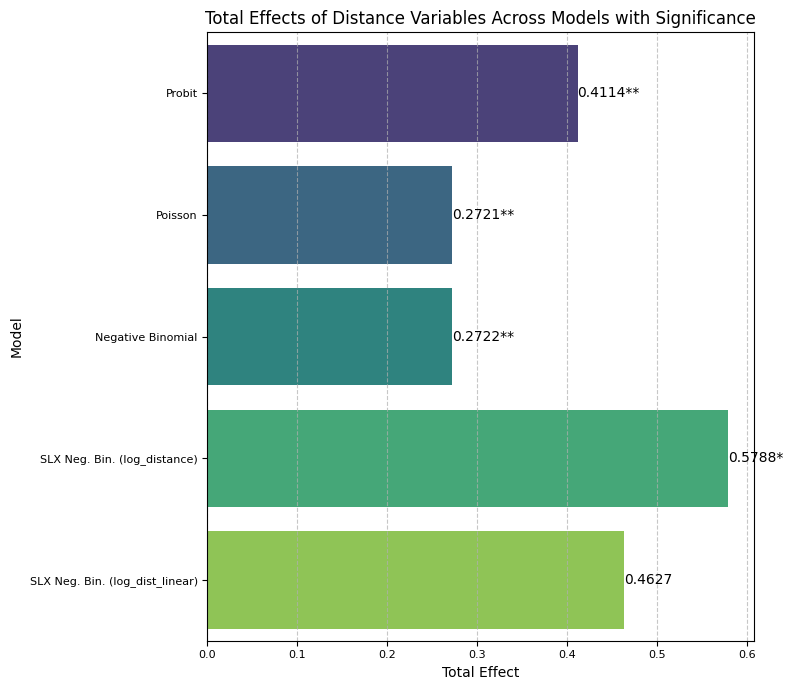

In [119]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the bar chart
fig = plt.figure(figsize=(8,7))
sns.barplot(x='Total Effect', y='Model', data=total_effects_df, hue='Model',
            palette='viridis', orient='h', legend=False)

# Add significance stars as text annotations next to the bars
for index, row in total_effects_df.iterrows():
    plt.text(row['Total Effect'], index,
             row['Formatted Total Effect'].split('**')[0].split('*')[0] +
             row['Formatted Total Effect'].replace(str(round(row['Total Effect'], 4)), ''),
             color='black', ha='left', va='center', fontsize=10)

plt.title('Total Effects of Distance Variables Across Models with Significance', fontsize=12)
plt.xlabel('Total Effect', fontsize=10)
plt.ylabel('Model', fontsize=10)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()